# 01 – First look at the order book

Run `python rebuild_book.py` first. This notebook loads its output and checks five things:
mid price, spread, trades, order book imbalance and latency.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TICK = 0.01  # BTCUSDT tick size on Binance spot

book = pd.read_parquet("data/processed/book")
trades = pd.read_parquet("data/processed/trades")
book["time"] = pd.to_datetime(book["event_ms"], unit="ms")
trades["time"] = pd.to_datetime(trades["trade_ms"], unit="ms")

print(f"{len(book):,} book updates, {len(trades):,} trades")
print("from", book.time.min(), "to", book.time.max())

2,588,980 book updates, 7,513,224 trades
from 2026-08-01 00:00:00.861000 to 2026-10-01 23:59:59.914000


## Mid price and spread

In [2]:
book["mid"] = (book.bid_px_0 + book.ask_px_0) / 2
book["spread"] = book.ask_px_0 - book.bid_px_0
book["spread_ticks"] = (book.spread / TICK).round().astype(int)

print("Spread in ticks (share of updates):")
print(book.spread_ticks.value_counts(normalize=True).sort_index().head(10).round(4))

Spread in ticks (share of updates):
spread_ticks
1     0.9996
2     0.0000
3     0.0000
4     0.0000
5     0.0000
6     0.0000
7     0.0000
8     0.0000
9     0.0000
10    0.0000
Name: proportion, dtype: float64


/Users/saindustries/Desktop/Lob Market Making/venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


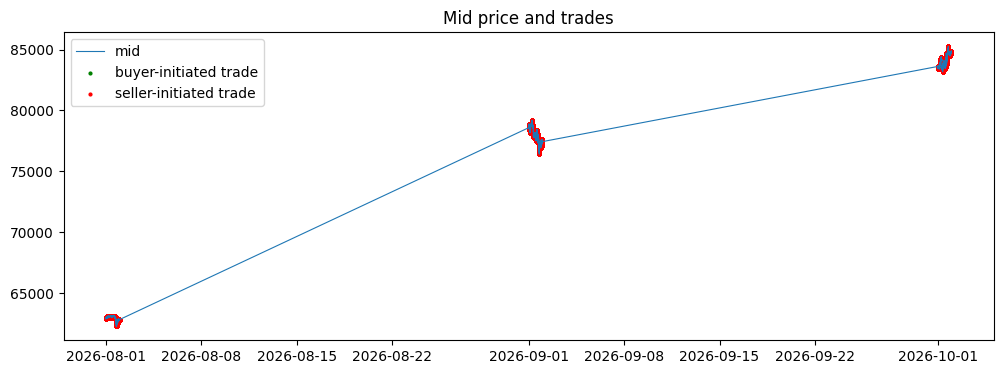

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(book.time, book.mid, lw=0.8, label="mid")
buys = trades[~trades.buyer_is_maker]   # aggressor was the buyer
sells = trades[trades.buyer_is_maker]   # aggressor was the seller
ax.scatter(buys.time, buys.price, s=4, c="green", label="buyer-initiated trade")
ax.scatter(sells.time, sells.price, s=4, c="red", label="seller-initiated trade")
ax.set_title("Mid price and trades"); ax.legend(); plt.show()

## Order book imbalance at the best level

Imbalance = (bid size − ask size) / (bid size + ask size), from −1 (all on the ask) to +1 (all on the bid).
Step 2 tests whether this predicts the next mid-price move.

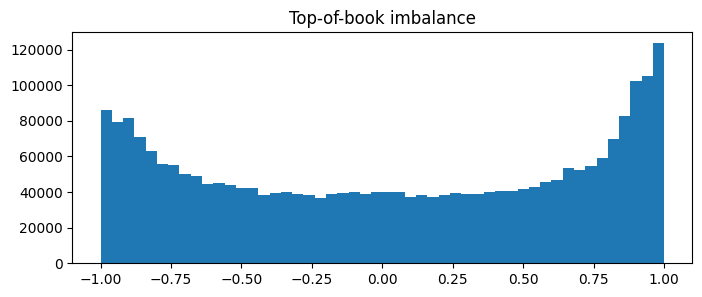

In [4]:
book["imbalance"] = (book.bid_qty_0 - book.ask_qty_0) / (book.bid_qty_0 + book.ask_qty_0)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(book.imbalance, bins=50)
ax.set_title("Top-of-book imbalance"); plt.show()

## Latency: exchange time vs. when you received it

Includes network delay and any difference between your Mac's clock and Binance's.

count    2588980.0
mean           2.7
std           14.2
min            0.2
50%            2.5
90%            3.3
99%            3.8
max         3874.7
dtype: float64


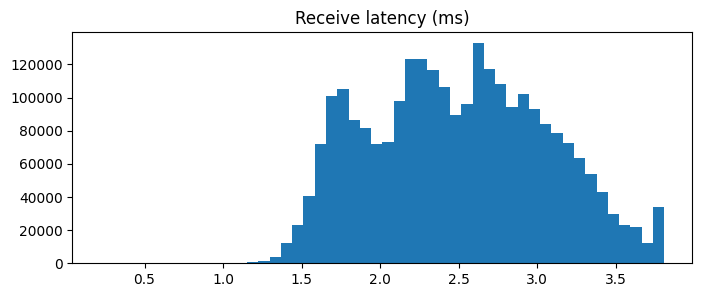

In [5]:
latency_ms = book.recv_ns / 1e6 - book.event_ms
print(latency_ms.describe(percentiles=[0.5, 0.9, 0.99]).round(1))

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(latency_ms.clip(upper=latency_ms.quantile(0.99)), bins=50)
ax.set_title("Receive latency (ms)"); plt.show()